In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

os.chdir("C:\\Users\\Prudhvi\\Documents\\data\\quora_qn_pairs")

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

C:\Users\Prudhvi\Anaconda2\lib\site-packages\IPython\core\interactiveshell.py:2723: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [20]:
train.head()

,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0


In [9]:
print "Number of questions comparisions are " , len(train)
print "Unique questions in train", len(np.unique(train.qid1 +train.qid2))

Number of questions comparisions are  404290
Unique questions in train 347345


In [5]:
print "Unique questions in test", len(np.unique(test.question1 +test.question2))

Unique questions in test

C:\Users\Prudhvi\Anaconda2\lib\site-packages\numpy\lib\arraysetops.py:200: FutureWarning: numpy not_equal will not check object identity in the future. The comparison did not return the same result as suggested by the identity (`is`)) and will change.
  flag = np.concatenate(([True], aux[1:] != aux[:-1]))


 2340394


There are 0.3 million questions in train and around 2.3 million questions in test

In [4]:
test.head()

,test_id,question1,question2
0,0,How does the Surface Pro himself 4 compare wit...,Why did Microsoft choose core m3 and not core ...
1,1,Should I have a hair transplant at age 24? How...,How much cost does hair transplant require?
2,2,What but is the best way to send money from Ch...,What you send money to China?
3,3,Which food not emulsifiers?,What foods fibre?
4,4,"How ""aberystwyth"" start reading?",How their can I start reading?


In [8]:
print len(np.unique(train.qid1)), " questions in qid1 occured for ", len(train.qid1)

290654  questions in qid1 occured for  404290


In [10]:
print len(np.unique(train.qid2)), " questions in qid2 occured for ", len(train.qid2)

299364  questions in qid2 occured for  404290


In [11]:
print "common questions in train for qid1 and qid2 are " , len(list(set(train.qid1).intersection(train.qid2)))

common questions in qid1 and qid2 are  52085


In [12]:
print "common questions in test for qid1 and qid2 are " , len(list(set(test.question1).intersection(test.question2)))

common questions in test for qid1 and qid2 are  74577


In [21]:
from collections import Counter
from __future__ import division
d = Counter(train.is_duplicate)
print "% of duplicates ", (d[1]/len(train))*100

% of duplicates  36.9197853026


In [27]:
train.dtypes

id               int64
qid1             int64
qid2             int64
question1       object
question2       object
is_duplicate     int64
q1_n_words       int64
dtype: object

In [29]:
train['q1_n_words'] = train['question1'].apply(lambda row: len(str(row).split(" ")))
train['q2_n_words'] = train['question2'].apply(lambda row: len(str(row).split(" ")))

def normalized_word_share(row):
    w1 = set(map(lambda word: word.lower().strip(), str(row['question1']).split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), str(row['question2']).split(" ")))    
    return 1.0 * len(w1 & w2)/(len(w1) + len(w2))


train['word_share'] = train.apply(normalized_word_share, axis=1)

train.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_n_words,q2_n_words,word_share
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,14,12,0.434783
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,8,13,0.200000
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,14,10,0.166667
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,11,9,0.000000
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,13,7,0.100000


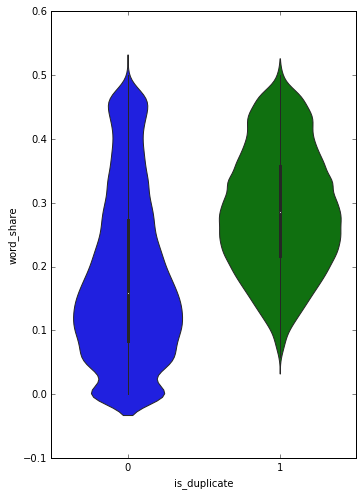

In [33]:
import seaborn as sns
plt.figure(figsize=(12, 8))
plt.subplot(1,2,1)
sns.violinplot(x = 'is_duplicate', y = 'word_share', data = train[0:50000])
